In [ ]:
!pip install -q earthengine-api geemap geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 47.5 MB/s eta 0:00:00


In [ ]:
import ee

ee.Authenticate()

In [ ]:
ee.Initialize(project='ictd-507010')

In [ ]:
print(ee.String('Earth Engine is working!').getInfo())

Earth Engine is working!


In [ ]:
import geopandas as gpd

gdf_2021 = gpd.read_file(
    "/content/partially_completely_burnt_2021_10_29.geojson"
)

gdf_2020 = gpd.read_file(
    "/content/partially_completely_burnt_2020_11_10.geojson"
)

print("2021 fields:", len(gdf_2021))
print("2020 fields:", len(gdf_2020))

print("\n2021 CRS:", gdf_2021.crs)
print("2020 CRS:", gdf_2020.crs)

print("\n2021 bounds:")
print(gdf_2021.total_bounds)

print("\n2020 bounds:")
print(gdf_2020.total_bounds)

2021 fields: 357
2020 fields: 81

2021 CRS: EPSG:4326
2020 CRS: EPSG:4326

2021 bounds:
[75.47743092 31.16499906 75.85111461 31.43344619]

2020 bounds:
[75.81263326 30.29706492 75.93362896 30.46198751]


In [ ]:
import geemap

roi_2021 = geemap.geopandas_to_ee(gdf_2021)
roi_2020 = geemap.geopandas_to_ee(gdf_2020)

print("2021 polygons:", roi_2021.size().getInfo())
print("2020 polygons:", roi_2020.size().getInfo())

2021 polygons: 357
2020 polygons: 81


In [ ]:
s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")

images_2021 = (
    s2
    .filterBounds(roi_2021.geometry())
    .filterDate("2021-10-28", "2021-10-31")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 50))
    .sort("CLOUDY_PIXEL_PERCENTAGE")
)

print("Number of images:", images_2021.size().getInfo())

Number of images: 1


In [ ]:
info_2021 = images_2021.aggregate_array("system:index").getInfo()
cloud_2021 = images_2021.aggregate_array("CLOUDY_PIXEL_PERCENTAGE").getInfo()

for img, cloud in zip(info_2021, cloud_2021):
    print(img, " | cloud:", cloud)

20211029T053941_20211029T053942_T43REQ  | cloud: 2.3e-05


In [ ]:
images_2020 = (
    s2
    .filterBounds(roi_2020.geometry())
    .filterDate("2020-11-09", "2020-11-12")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 50))
    .sort("CLOUDY_PIXEL_PERCENTAGE")
)

print("Number of images:", images_2020.size().getInfo())

Number of images: 1


In [ ]:
info_2020 = images_2020.aggregate_array("system:index").getInfo()
cloud_2020 = images_2020.aggregate_array("CLOUDY_PIXEL_PERCENTAGE").getInfo()

for img, cloud in zip(info_2020, cloud_2020):
    print(img, " | cloud:", cloud)

20201110T053041_20201110T053044_T43REP  | cloud: 12.732081


In [ ]:
# Get the selected images
img_2021 = ee.Image(
    "COPERNICUS/S2_SR_HARMONIZED/20211029T053941_20211029T053942_T43REQ"
)

img_2020 = ee.Image(
    "COPERNICUS/S2_SR_HARMONIZED/20201110T053041_20201110T053044_T43REP"
)

print("2021 image:", img_2021.get("system:index").getInfo())
print("2020 image:", img_2020.get("system:index").getInfo())

print("\n2021 footprint:")
print(img_2021.geometry().bounds().getInfo())

print("\n2020 footprint:")
print(img_2020.geometry().bounds().getInfo())

2021 image: 20211029T053941_20211029T053942_T43REQ
2020 image: 20201110T053041_20201110T053044_T43REP

2021 footprint:
{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[74.99968343933908, 30.639863194268976], [76.15748065523651, 30.639863194268976], [76.15748065523651, 31.63563709220961], [74.99968343933908, 31.63563709220961], [74.99968343933908, 30.639863194268976]]]}

2020 footprint:
{'geodesic': False, 'type': 'Polygon', 'coordinates': [[[75.68408347152102, 29.73742710452514], [76.14655460185053, 29.73742710452514], [76.14655460185053, 30.72978459391513], [75.68408347152102, 30.72978459391513], [75.68408347152102, 29.73742710452514]]]}


In [ ]:
intersect_2021 = roi_2021.filterBounds(img_2021.geometry())
intersect_2020 = roi_2020.filterBounds(img_2020.geometry())

print("2021 fields covered:", intersect_2021.size().getInfo())
print("2020 fields covered:", intersect_2020.size().getInfo())

2021 fields covered: 357
2020 fields covered: 79


In [ ]:
# Find the 2020 reference fields that are NOT covered
covered_ids = intersect_2020.aggregate_array("field_id").getInfo()

all_2020 = roi_2020.aggregate_array("field_id").getInfo()

missing_ids = [x for x in all_2020 if x not in covered_ids]

print("Missing field IDs:", missing_ids)

Missing field IDs: [30, 40]


In [ ]:
missing_2020 = roi_2020.filter(
    ee.Filter.inList("field_id", missing_ids)
)

print(
    missing_2020
    .aggregate_array("field_category")
    .getInfo()
)

print(
    missing_2020
    .geometry()
    .centroid()
    .coordinates()
    .getInfo()
)

['partially_burnt', 'partially_burnt']
[75.818496139425, 30.458895601966006]


In [ ]:
missing_images_2020 = (
    s2
    .filterBounds(missing_2020.geometry())
    .filterDate("2020-11-09", "2020-11-12")
    .sort("CLOUDY_PIXEL_PERCENTAGE")
)

print(
    "Images covering missing fields:",
    missing_images_2020.size().getInfo()
)

ids = missing_images_2020.aggregate_array("system:index").getInfo()
clouds = missing_images_2020.aggregate_array(
    "CLOUDY_PIXEL_PERCENTAGE"
).getInfo()

for img, cloud in zip(ids, clouds):
    print(img, "| cloud:", cloud)

Images covering missing fields: 0


In [ ]:
# ============================================================
# STEP 14: Create NBR, BAIS2 and TCB images
# ============================================================

def prepare_indices(image):

    # Sentinel-2 SR is scaled by 10000
    bands = [
        'B2', 'B3', 'B4',
        'B6', 'B7', 'B8', 'B8A',
        'B11', 'B12'
    ]

    sr = image.select(bands).divide(10000)

    # --------------------------------------------------------
    # SCL mask
    # Keep:
    #   4 = vegetation
    #   5 = bare soil
    #
    # Remove clouds, shadows, water, etc.
    # --------------------------------------------------------
    scl = image.select('SCL')

    valid = (
        scl.eq(4)
        .Or(scl.eq(5))
    )

    sr = sr.updateMask(valid)

    # --------------------------------------------------------
    # NBR
    # --------------------------------------------------------
    nbr = (
        sr.select('B8')
        .subtract(sr.select('B12'))
        .divide(
            sr.select('B8')
            .add(sr.select('B12'))
        )
        .rename('NBR')
    )

    # --------------------------------------------------------
    # BAIS2
    #
    # BAIS2 =
    # (1 - sqrt(B6*B7*B8A / B4))
    # *
    # ((B12-B8A)/sqrt(B12+B8A) + 1)
    # --------------------------------------------------------

    bais2_part1 = (
        sr.select('B6')
        .multiply(sr.select('B7'))
        .multiply(sr.select('B8A'))
        .divide(sr.select('B4'))
        .sqrt()
    )

    bais2_part2 = (
        sr.select('B12')
        .subtract(sr.select('B8A'))
        .divide(
            sr.select('B12')
            .add(sr.select('B8A'))
            .sqrt()
        )
        .add(1)
    )

    bais2 = (
        ee.Image(1)
        .subtract(bais2_part1)
        .multiply(bais2_part2)
        .rename('BAIS2')
    )

    # --------------------------------------------------------
    # Tasseled Cap Brightness (TCB)
    # --------------------------------------------------------

    tcb = (
        sr.select('B2').multiply(0.3510)
        .add(sr.select('B3').multiply(0.3813))
        .add(sr.select('B4').multiply(0.3437))
        .add(sr.select('B8').multiply(0.7196))
        .add(sr.select('B11').multiply(0.2396))
        .add(sr.select('B12').multiply(0.1949))
        .rename('TCB')
    )

    return nbr.addBands(bais2).addBands(tcb)


indices_2021 = prepare_indices(img_2021)
indices_2020 = prepare_indices(img_2020)

print("Indices created successfully.")
print(indices_2021.bandNames().getInfo())

Indices created successfully.
['NBR', 'BAIS2', 'TCB']


In [ ]:
# ============================================================
# STEP 15: Extract field-level median indices
# ============================================================

def extract_field_values(index_image, fields):

    results = index_image.reduceRegions(
        collection=fields,
        reducer=ee.Reducer.median(),
        scale=20,
        tileScale=4
    )

    return results


results_2021 = extract_field_values(
    indices_2021,
    intersect_2021
)

results_2020 = extract_field_values(
    indices_2020,
    intersect_2020
)

print("2021 results:", results_2021.size().getInfo())
print("2020 results:", results_2020.size().getInfo())

2021 results: 357
2020 results: 79


In [ ]:
sample_2021 = results_2021.limit(10).getInfo()

for feature in sample_2021['features']:
    print(feature['properties'])

{'BAIS2': 0.7995346390391352, 'NBR': -0.06731027323540423, 'TCB': 0.320814499056704, 'field_category': 'completely_burnt', 'field_id': 1, 'field_name': 'complete_1'}
{'BAIS2': 0.741777446417713, 'NBR': 0.08352001678120145, 'TCB': 0.27603013905670404, 'field_category': 'completely_burnt', 'field_id': 2, 'field_name': 'complete_2'}
{'BAIS2': 0.8377961333380853, 'NBR': -0.05575327083818955, 'TCB': 0.30974215004182104, 'field_category': 'completely_burnt', 'field_id': 3, 'field_name': 'complete_3'}
{'BAIS2': 0.8975616163015399, 'NBR': -0.10729314509259069, 'TCB': 0.2388216610873461, 'field_category': 'completely_burnt', 'field_id': 4, 'field_name': 'complete_4'}
{'BAIS2': 0.87633663876046, 'NBR': -0.09652958350565295, 'TCB': 0.2860986187453699, 'field_category': 'completely_burnt', 'field_id': 5, 'field_name': 'complete_5'}
{'BAIS2': 0.8646889233154738, 'NBR': -0.08788053461492146, 'TCB': 0.29075111131968495, 'field_category': 'completely_burnt', 'field_id': 6, 'field_name': 'complete_6'}


In [ ]:
import pandas as pd
import numpy as np

# Convert GEE FeatureCollections to Python
data_2021 = results_2021.getInfo()
data_2020 = results_2020.getInfo()

def features_to_df(ee_result, year):
    rows = []

    for f in ee_result["features"]:
        p = f["properties"].copy()
        p["year"] = year
        rows.append(p)

    return pd.DataFrame(rows)

df_2021 = features_to_df(data_2021, 2021)
df_2020 = features_to_df(data_2020, 2020)

df = pd.concat([df_2021, df_2020], ignore_index=True)

print("Total fields:", len(df))
print("\nClasses:")
print(df["field_category"].value_counts())

print("\nMissing values:")
print(df[["NBR", "BAIS2", "TCB"]].isna().sum())

Total fields: 436

Classes:
field_category
partially_burnt          226
unburnt                   95
completely_burnt          90
golden_yellow_unburnt     13
green_unburnt             12
Name: count, dtype: int64

Missing values:
NBR      56
BAIS2    56
TCB      56
dtype: int64


In [ ]:
burned_classes = [
    "completely_burnt",
    "partially_burnt"
]

df["ground_truth"] = (
    df["field_category"]
    .isin(burned_classes)
    .astype(int)
)

print(
    df["ground_truth"]
    .value_counts()
    .rename({0: "Unburned", 1: "Burned"})
)

ground_truth
Burned      316
Unburned    120
Name: count, dtype: int64


In [ ]:
summary = df.groupby("ground_truth")[["NBR", "BAIS2", "TCB"]].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(summary)

               NBR                                                   BAIS2  \
             count      mean    median       std       min       max count   
ground_truth                                                                 
0              115  0.149726  0.082288  0.152549 -0.137356  0.548880   115   
1              265 -0.027634 -0.033631  0.090495 -0.384306  0.275575   265   

                                                                 TCB  \
                  mean    median       std       min       max count   
ground_truth                                                           
0             0.562989  0.596272  0.109553  0.194306  0.823580   115   
1             0.804414  0.809951  0.079791  0.549308  1.076906   265   

                                                                
                  mean    median       std       min       max  
ground_truth                                                    
0             0.464038  0.476638  0.085749  0.255942 

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve

# Remove fields with missing values
df_valid = df.dropna(subset=["NBR", "BAIS2", "TCB"]).copy()

y = df_valid["ground_truth"]

# NBR: lower = more likely burned
auc_nbr = roc_auc_score(y, -df_valid["NBR"])

# BAIS2: higher = more likely burned
auc_bais2 = roc_auc_score(y, df_valid["BAIS2"])

# TCB: lower = more likely burned
auc_tcb = roc_auc_score(y, -df_valid["TCB"])

print("Valid fields:", len(df_valid))
print("NBR AUC:", auc_nbr)
print("BAIS2 AUC:", auc_bais2)
print("TCB AUC:", auc_tcb)

Valid fields: 380
NBR AUC: 0.8829204265791634
BAIS2 AUC: 0.9761771944216571
TCB AUC: 0.951960623461854


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use only complete observations
df_valid = df.dropna(
    subset=["NBR", "BAIS2", "TCB", "ground_truth"]
).copy()

X = df_valid[["BAIS2", "TCB"]]
y = df_valid["ground_truth"]

# Logistic regression
model = LogisticRegression()
model.fit(X, y)

# Probability of burned
prob_burned = model.predict_proba(X)[:, 1]

# Default threshold = 0.5
pred = (prob_burned >= 0.5).astype(int)

print("BAIS2 + TCB coefficients:")
print("BAIS2:", model.coef_[0][0])
print("TCB:", model.coef_[0][1])

print("\nAUC:", roc_auc_score(y, prob_burned))
print("Accuracy:", accuracy_score(y, pred))
print("Precision:", precision_score(y, pred))
print("Recall:", recall_score(y, pred))
print("F1:", f1_score(y, pred))

print("\nConfusion matrix:")
print(confusion_matrix(y, pred))

BAIS2 + TCB coefficients:
BAIS2: 6.58115478844435
TCB: -5.400290227626429

AUC: 0.9914356029532403
Accuracy: 0.9342105263157895
Precision: 0.9225352112676056
Recall: 0.9886792452830189
F1: 0.9544626593806922

Confusion matrix:
[[ 93  22]
 [  3 262]]


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ---------------------------------------------------------
# Prepare data
# ---------------------------------------------------------

df_valid = df.dropna(
    subset=["NBR", "BAIS2", "TCB", "ground_truth"]
).copy()

y = df_valid["ground_truth"]

# Same folds for both methods
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ---------------------------------------------------------
# METHOD 1: NBR
# Lower NBR = more likely burned
# We use -NBR so higher probability corresponds to burned.
# ---------------------------------------------------------

X_nbr = df_valid[["NBR"]]

nbr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

nbr_prob = cross_val_predict(
    nbr_model,
    X_nbr,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

nbr_pred = (nbr_prob >= 0.5).astype(int)

# ---------------------------------------------------------
# METHOD 2: BAIS2 + TCB
# ---------------------------------------------------------

X_bais_tcb = df_valid[["BAIS2", "TCB"]]

bais_tcb_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

bais_tcb_prob = cross_val_predict(
    bais_tcb_model,
    X_bais_tcb,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

bais_tcb_pred = (bais_tcb_prob >= 0.5).astype(int)

# ---------------------------------------------------------
# Evaluation function
# ---------------------------------------------------------

def evaluate(name, y, prob, pred):

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("ROC-AUC :", round(roc_auc_score(y, prob), 4))
    print("Accuracy:", round(accuracy_score(y, pred), 4))
    print("Precision:", round(precision_score(y, pred), 4))
    print("Recall:", round(recall_score(y, pred), 4))
    print("F1:", round(f1_score(y, pred), 4))

    print("\nConfusion matrix:")
    print(confusion_matrix(y, pred))


# ---------------------------------------------------------
# Results
# ---------------------------------------------------------

evaluate(
    "NBR",
    y,
    nbr_prob,
    nbr_pred
)

evaluate(
    "BAIS2 + TCB",
    y,
    bais_tcb_prob,
    bais_tcb_pred
)


NBR
ROC-AUC : 0.8816
Accuracy: 0.7816
Precision: 0.7974
Recall: 0.9208
F1: 0.8546

Confusion matrix:
[[ 53  62]
 [ 21 244]]

BAIS2 + TCB
ROC-AUC : 0.9903
Accuracy: 0.9553
Precision: 0.9559
Recall: 0.9811
F1: 0.9683

Confusion matrix:
[[103  12]
 [  5 260]]


In [ ]:
from sklearn.model_selection import StratifiedKFold

# Use the same 5-fold strategy for the whole experiment
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold cross-validation is ready.")
print("Each field will be tested once as unseen data.")

5-fold cross-validation is ready.
Each field will be tested once as unseen data.


In [33]:
import numpy as np

# Use the SAME 380 fields as BAIS2 + TCB
df_bais_tcb = df.dropna(
    subset=["NBR", "BAIS2", "TCB", "ground_truth"]
).copy()

print("Fields used for NBR:", len(df_bais_tcb))

# Store predictions made on unseen test fields
nbr_true = []
nbr_pred = []
nbr_thresholds = []

for train_idx, test_idx in cv.split(
    df_bais_tcb,
    df_bais_tcb["ground_truth"]
):

    train = df_bais_tcb.iloc[train_idx]
    test = df_bais_tcb.iloc[test_idx]

    # Try many possible NBR thresholds using ONLY training data
    thresholds = np.linspace(
        train["NBR"].min(),
        train["NBR"].max(),
        500
    )

    best_threshold = None
    best_accuracy = -1

    for threshold in thresholds:

        # Lower NBR → more likely burned
        train_pred = (
            train["NBR"] < threshold
        ).astype(int)

        accuracy = np.mean(
            train_pred == train["ground_truth"]
        )

        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_threshold = threshold

    # Freeze threshold learned from training data
    test_pred = (
        test["NBR"] < best_threshold
    ).astype(int)

    # Store unseen-test predictions
    nbr_true.extend(test["ground_truth"].values)
    nbr_pred.extend(test_pred.values)
    nbr_thresholds.append(best_threshold)

print("NBR threshold learning completed.")
print("Threshold learned in each fold:")
print(np.round(nbr_thresholds, 4))

Fields used for NBR: 380
NBR threshold learning completed.
Threshold learned in each fold:
[0.0439 0.0439 0.0448 0.0439 0.0381]


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Use only fields where BOTH BAIS2 and TCB are available
df_bais_tcb = df.dropna(
    subset=["BAIS2", "TCB"]
).copy()

print("Fields available for BAIS2 + TCB:", len(df_bais_tcb))

bais_tcb_true = []
bais_tcb_pred = []

bais_tcb_models = []

for train_idx, test_idx in cv.split(
    df_bais_tcb,
    df_bais_tcb["ground_truth"]
):

    train = df_bais_tcb.iloc[train_idx]
    test = df_bais_tcb.iloc[test_idx]

    # Features
    X_train = train[["BAIS2", "TCB"]]
    X_test = test[["BAIS2", "TCB"]]

    y_train = train["ground_truth"]
    y_test = test["ground_truth"]

    # Standardize using training data only
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Learn decision boundary using training data only
    model = LogisticRegression(
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    # Predict unseen test fields
    test_pred = model.predict(X_test_scaled)

    # Store predictions
    bais_tcb_true.extend(y_test.values)
    bais_tcb_pred.extend(test_pred)

    bais_tcb_models.append(model)

print("BAIS2 + TCB decision boundary learning completed.")
print("5 fold models learned and tested on unseen fields.")

Fields available for BAIS2 + TCB: 380
BAIS2 + TCB decision boundary learning completed.
5 fold models learned and tested on unseen fields.


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# NBR performance
nbr_accuracy = accuracy_score(nbr_true, nbr_pred)
nbr_precision = precision_score(nbr_true, nbr_pred)
nbr_recall = recall_score(nbr_true, nbr_pred)
nbr_f1 = f1_score(nbr_true, nbr_pred)
nbr_cm = confusion_matrix(nbr_true, nbr_pred)

# BAIS2 + TCB performance
bais_tcb_accuracy = accuracy_score(
    bais_tcb_true,
    bais_tcb_pred
)
bais_tcb_precision = precision_score(
    bais_tcb_true,
    bais_tcb_pred
)
bais_tcb_recall = recall_score(
    bais_tcb_true,
    bais_tcb_pred
)
bais_tcb_f1 = f1_score(
    bais_tcb_true,
    bais_tcb_pred
)
bais_tcb_cm = confusion_matrix(
    bais_tcb_true,
    bais_tcb_pred
)

print("=" * 50)
print("NBR")
print("=" * 50)

print(f"Accuracy : {nbr_accuracy:.4f}")
print(f"Precision: {nbr_precision:.4f}")
print(f"Recall   : {nbr_recall:.4f}")
print(f"F1-score : {nbr_f1:.4f}")

print("\nConfusion Matrix:")
print(nbr_cm)


print("\n" + "=" * 50)
print("BAIS2 + TCB")
print("=" * 50)

print(f"Accuracy : {bais_tcb_accuracy:.4f}")
print(f"Precision: {bais_tcb_precision:.4f}")
print(f"Recall   : {bais_tcb_recall:.4f}")
print(f"F1-score : {bais_tcb_f1:.4f}")

print("\nConfusion Matrix:")
print(bais_tcb_cm)

NBR
Accuracy : 0.8132
Precision: 0.9008
Recall   : 0.8226
F1-score : 0.8600

Confusion Matrix:
[[ 91  24]
 [ 47 218]]

BAIS2 + TCB
Accuracy : 0.9553
Precision: 0.9559
Recall   : 0.9811
F1-score : 0.9683

Confusion Matrix:
[[103  12]
 [  5 260]]


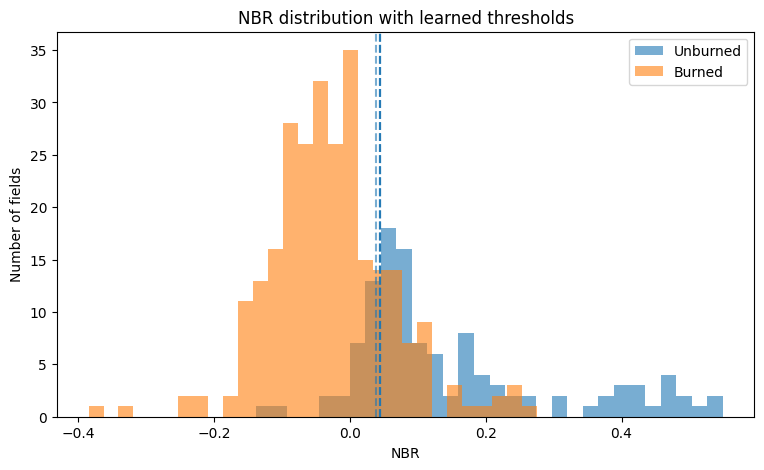

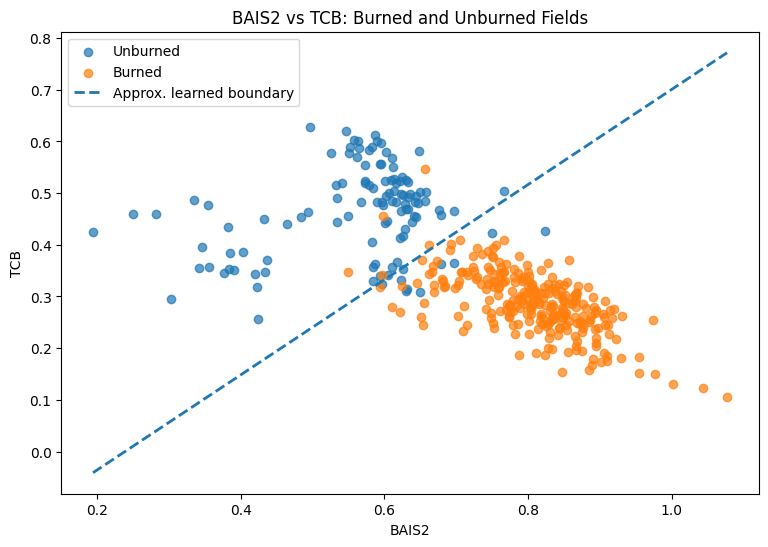

In [36]:
import matplotlib.pyplot as plt

# Use the 380 fields with valid values
plot_df = df.dropna(
    subset=["NBR", "BAIS2", "TCB", "ground_truth"]
).copy()

# ---------------------------------------------------------
# Plot 1: NBR distributions
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.hist(
    plot_df.loc[plot_df["ground_truth"] == 0, "NBR"],
    bins=30,
    alpha=0.6,
    label="Unburned"
)

plt.hist(
    plot_df.loc[plot_df["ground_truth"] == 1, "NBR"],
    bins=30,
    alpha=0.6,
    label="Burned"
)

for threshold in nbr_thresholds:
    plt.axvline(
        threshold,
        linestyle="--",
        alpha=0.6
    )

plt.xlabel("NBR")
plt.ylabel("Number of fields")
plt.title("NBR distribution with learned thresholds")
plt.legend()
plt.show()


# ---------------------------------------------------------
# Plot 2: BAIS2 vs TCB
# ---------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    plot_df.loc[plot_df["ground_truth"] == 0, "BAIS2"],
    plot_df.loc[plot_df["ground_truth"] == 0, "TCB"],
    alpha=0.7,
    label="Unburned"
)

plt.scatter(
    plot_df.loc[plot_df["ground_truth"] == 1, "BAIS2"],
    plot_df.loc[plot_df["ground_truth"] == 1, "TCB"],
    alpha=0.7,
    label="Burned"
)

# Use the average model coefficients/intercept
coef = np.mean(
    [m.coef_[0] for m in bais_tcb_models],
    axis=0
)

intercept = np.mean(
    [m.intercept_[0] for m in bais_tcb_models]
)

scaler = StandardScaler()
scaler.fit(plot_df[["BAIS2", "TCB"]])

# Create BAIS2 values for plotting
x_vals = np.linspace(
    plot_df["BAIS2"].min(),
    plot_df["BAIS2"].max(),
    200
)

# Convert BAIS2 to standardized values
x_scaled = (
    x_vals - scaler.mean_[0]
) / scaler.scale_[0]

# Logistic boundary:
# coef[0]*BAIS2_scaled + coef[1]*TCB_scaled + intercept = 0

y_scaled = (
    -(coef[0] * x_scaled + intercept)
    / coef[1]
)

y_vals = (
    y_scaled * scaler.scale_[1]
    + scaler.mean_[1]
)

plt.plot(
    x_vals,
    y_vals,
    linestyle="--",
    linewidth=2,
    label="Approx. learned boundary"
)

plt.xlabel("BAIS2")
plt.ylabel("TCB")
plt.title("BAIS2 vs TCB: Burned and Unburned Fields")
plt.legend()
plt.show()